# Diagnosing and correcting an LLM fact-checking pipeline

**LIAR-Triage, notebook 2: the correction story**

This notebook follows one evaluation cycle from start to finish:

1. **Baseline:** how the first version (v1) performed on 50 real PolitiFact claims
2. **Diagnosis:** six problems, each shown with evidence from the data
3. **The fixes:** what changed in the prompt and the API call (v2)
4. **The rerun:** v2 on the *same* 50 claims
5. **Before vs after:** what improved, what didn't, and which answers flipped
6. **Held-out check:** v2 on 50 *new* claims, to test whether the fixes generalise
7. **Conclusions** and limitations

**How to use:** keep this notebook in the project folder (next to `pipeline.py`, `evaluate.py`, `.env`
and `data/test.tsv`) and choose **Run All**. The v1 results from your first run are reused, not re-sent.

## Setup

In [1]:
%pip install -q openai python-dotenv pydantic pandas matplotlib

import importlib
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import pipeline, evaluate as ev
importlib.reload(pipeline); importlib.reload(ev)   # pick up any edits to the .py files

pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 200)

PROVIDER = "groq"
RUN_V2 = True        # set False to skip sending claims and only re-analyse saved results
RUN_HOLDOUT = True   # Chapter 6: 50 unseen claims (about 10 more minutes on the free tier)
WORKERS = 1          # 1 is gentlest on the free rate limit

for f in ["pipeline.py", "evaluate.py", ".env", "data/test.tsv", pipeline.results_path(PROVIDER, "v1")]:
    print(("OK      " if Path(f).exists() else "MISSING ") + str(f))


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
OK      pipeline.py
OK      evaluate.py
OK      .env
OK      data/test.tsv
OK      results\groq_openai-gpt-oss-20b.jsonl


---
## 1. Baseline (v1)

v1 asked the model for a verdict, a confidence score and a short rationale, using only the claim and
the speaker's name. Here is how it did.

In [2]:
V1 = pipeline.results_path(PROVIDER, "v1")
v1_df = ev.load_results(V1)
v1 = ev.flatten_ok(v1_df)

pd.Series(ev.health(v1_df), name="v1").to_frame()

C:\Users\Emma\Documents\self\RESEARCH PROJECTS\llm-misinfo-triage\evaluate.py:87: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  toks = (df["prompt_tokens"].fillna(0) + df["completion_tokens"].fillna(0))


,v1
claims,50.00
usable answers,45.00
failure rate,0.10
empty replies,5.00
rate-limited claims,13.00
median latency (s),4.84
mean tokens per call,NaN


In [3]:
pd.Series(ev.metrics(v1), name="v1").to_frame()

,v1
accuracy (6-class),0.267
macro-F1 (6-class),0.125
baseline acc (6-class),0.311
accuracy (binary),0.600
macro-F1 (binary),0.575
baseline acc (binary),0.511
share predicted 'false',0.733
share actually 'false',0.311
calibration error (ECE),0.278
confident (>=0.9) & wrong,13.000


**Reading the baseline**
- On the exact six-way rating, v1 scores *below* the "always guess the most common label" baseline.
- On the simpler true-leaning vs false-leaning split, it beats the baseline only modestly.
- It says "false" far more often than PolitiFact does.

Accuracy alone doesn't explain *why*. The next chapter does.

---
## 2. Diagnosis: six problems, with evidence

### Problem 1: empty replies
gpt-oss-20b is a *reasoning* model: it "thinks" before answering. Sometimes it spends the whole reply on
hidden reasoning and returns no visible text.

In [4]:
empties = v1_df[(v1_df["status"] != "ok") & (v1_df["raw"].fillna("") == "")]
print(f"{len(empties)} of {len(v1_df)} replies were completely empty")
empties[["id", "statement", "latency_s"]]

5 of 50 replies were completely empty


,id,statement,latency_s
7,9801.json,"Before I was state treasurer, my Rhode Island business helped create over 1,000 jobs.",2.46
17,7780.json,"Over the last several months, there was a review board headed by two distinguished Americans, Mike Mullen and Tom Pickering, who investi...",2.51
19,1777.json,"Ms. Kagan has spent her entire professional career in Harvard Square, Hyde Park and the D.C. Beltway.",11.14
30,2162.json,"When Atlanta Police Chief George Turner was interim head of the department, overall crime fell 14 percent and violent crime dropped 22.7...",3.81
36,6513.json,"The Obama administration leaked information, deliberately or otherwise, that led to the identification of the Pakistani doctor that help...",14.12


### Problem 2: rate limits
Groq's free tier allows 8,000 tokens per minute. Hidden reasoning makes each call expensive, so v1 hit
the limit repeatedly. The retry logic recovered, but it slows everything down.

In [5]:
limited = v1_df[v1_df["error"].fillna("").str.contains("429")]
print(f"{len(limited)} claims hit the rate limit at least once; all were retried")
limited["error"].str.extract(r"Requested (\d+)")[0].astype(float).describe()[["min", "mean", "max"]].rename("tokens requested per call")

13 claims hit the rate limit at least once; all were retried


min      874.000000
mean    1859.615385
max     2322.000000
Name: tokens requested per call, dtype: float64

### Problem 3: a strong bias toward "false"
Compare how often each rating was given by PolitiFact and by the model.

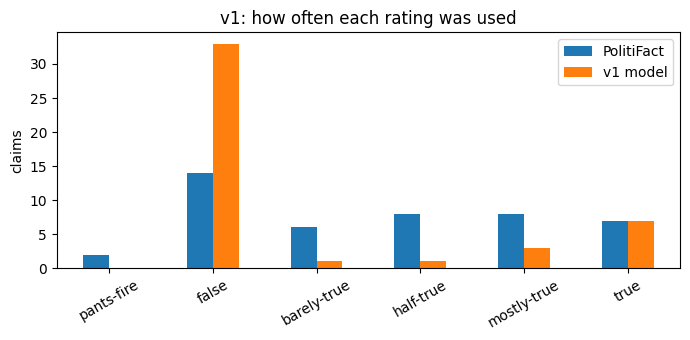

Of 23 claims PolitiFact rated true-leaning, v1 called 15 false-leaning.


In [6]:
dist = pd.DataFrame({
    "PolitiFact": v1["gold_label"].value_counts(),
    "v1 model": v1["verdict"].value_counts(),
}).reindex(ev.LABELS).fillna(0).astype(int)
ax = dist.plot.bar(figsize=(7, 3.5), rot=30, title="v1: how often each rating was used")
ax.set_ylabel("claims"); plt.tight_layout(); plt.show()

tl = v1[v1["gold_bin"] == "true-leaning"]
print(f"Of {len(tl)} claims PolitiFact rated true-leaning, v1 called {(tl['pred_bin'] == 'false-leaning').sum()} false-leaning.")

### Problem 4: confidence that means nothing
If confidence were meaningful, answers given at 0.9 confidence would be right about 90% of the time.

In [7]:
ev.calibration_table(v1)

,answers,mean_confidence,accuracy
confidence,,,
"(-0.001, 0.5]",4,0.25,0.50
"(0.5, 0.7]",5,0.70,0.60
"(0.7, 0.85]",4,0.81,0.75
"(0.85, 1.0]",32,0.93,0.59


In [8]:
v1[(v1["confidence"] >= 0.9) & ~v1["correct_bin"]][["statement", "gold_label", "verdict", "confidence"]].head(6)

,statement,gold_label,verdict,confidence
0,Nearly 20% of our residents are born abroad.,true,false,0.95
1,A child born in America today will inherit $1.5 million in debt the moment theyre placed in their mothers arms.,mostly-true,false,0.95
3,America is No. 1 in wind power.,mostly-true,false,0.95
7,"He received ""A"" ratings from ""every conservative organization that gives ratings.""",mostly-true,false,0.90
8,"The Hyde Amendmentlanguage was in the (human trafficking) bill. The Democratic sponsor admits it was in the bill, and she voted for it.",mostly-true,false,0.90
10,The tax cut deal is giving $700 billion to millionaires and billionaires.,false,true,0.90


### Problem 5: judging old claims with today's knowledge
LIAR claims were made between 2007 and 2016, but v1 was never told that. Some rationales cite later events.

In [9]:
v1[v1["anachronism"]][["statement", "gold_label", "verdict", "rationale"]]

,statement,gold_label,verdict,rationale
10,The tax cut deal is giving $700 billion to millionaires and billionaires.,false,true,"The 2023 bipartisan tax cut deal allocated roughly $700 billion in tax cuts for wealthy individuals, matching the claim that the deal gi..."
11,"In 1993, Newt Gingrich first advocated for the individual mandate in health care. And as recently as May of this year, he was still advo...",mostly-true,true,"Newt Gingrich introduced the 1993 Health Insurance Reform Act, which included an individual mandate, making him the first to advocate fo..."
25,Says Barack Obama is the first president in modern history not to have a single year of 3 percent growth.,mostly-true,true,"During Obama's eight years in office (2009‑2017) no single year reached 3% or higher GDP growth, and no earlier U.S. president in the po..."
27,Two million more Latinos are in poverty today than when President Obamatook his oath of office less than eight years ago.,half-true,mostly-true,U.S. Census data show that the Latino population in poverty rose from roughly 7.7 million in 2009 to about 9.3 million in 2017—a differe...
33,"In the four years before I became governor, we increased state debt $5.2 billion. Weve paid it down $2 billion.",half-true,mostly-true,"Florida’s general obligation debt rose from roughly $30.5 billion in 2007 to $35.7 billion in 2011, an increase of about $5.2 billion, a..."
40,"""The House has never failed to pass a budget in the modern era.""",true,false,"The U.S. House of Representatives has failed to pass budget resolutions on multiple occasions in recent decades (e.g., 2011, 2013, 2018‑..."


### Problem 6: "I don't know" treated as "false", and untraceable sources
Some claims were rated false only because the model couldn't recall them ("no evidence", "no public record").
Others cite precise studies or figures with no way to check them, which is a source-handling risk.

In [10]:
pattern = r"no (?:evidence|public record|credible|record)"
absence = v1[v1["rationale"].str.contains(pattern, case=False) & (v1["pred_bin"] == "false-leaning")]
print(f"{len(absence)} false-leaning verdicts rest on 'no evidence' reasoning; "
      f"{(~absence['correct_bin']).sum()} of them are wrong")
absence[["statement", "gold_label", "verdict", "confidence", "rationale"]]

12 false-leaning verdicts rest on 'no evidence' reasoning; 5 of them are wrong


,statement,gold_label,verdict,confidence,rationale
2,"If you and I fail to defund ObamaCare now, some 16,000 new IRS agents will be begin prying into our private medical records, eyeing each...",pants-fire,false,0.95,"There is no evidence that defunding the Affordable Care Act would trigger the IRS to hire 16,000 new agents to audit private medical rec..."
4,"Says I am happy to decline PERS so that the County can save over $68,000 over a four year term that would have been paid on my behalf.",half-true,false,0.30,"There is no evidence that John Ludlow publicly stated he declined a PERS plan to save the county over $68,000 in four years; the claim a..."
6,I am the only senator who turned down the state pension plan for part-time legislators.,true,false,0.30,"There is no public record or credible source indicating that any state senator, including Don Balfour, declined the state pension plan f..."
7,"He received ""A"" ratings from ""every conservative organization that gives ratings.""",mostly-true,false,0.90,"While Tom Tancredo has received high ratings from some conservative groups, no evidence shows he earned an ‘A’ from every conservative o..."
9,Say71 percent of doctors say Hillarys health concerns are serious and could be disqualifying.,false,false,0.20,No credible poll or reputable source reports that 71 % of doctors say Hillary Clinton’s health concerns are serious and disqualifying; t...
13,Barack Obama has provided guns to Mexican drug cartels.,half-true,false,0.95,There is no credible evidence that President Obama ever supplied firearms to Mexican drug cartels; the claim is a known conspiracy theory.
15,Fifty-seven of Rubios 100 ideas ultimately became law.,half-true,false,0.90,There is no evidence that Senator Rubio had a documented list of 100 ideas or that 57 of them became law; the claim appears to be a rhet...
23,Foreign Chinese prostitution money is allegedly behind the groups funding Congressman Sean Duffys Republican Majority.,pants-fire,false,0.20,There is no credible evidence that foreign Chinese prostitution money is funding groups that support Congressman Sean Duffys; the claim ...
29,"Like me, Scott Walker opposed the 1998 transportation bill and the $9 billion of wasteful spending.",false,false,0.70,There is no evidence that Scott Walker opposed the 1998 Transportation Equity Act for the 21st Century (TEA‑21) or its $9 billion fundin...
38,Over half the people on disability are either anxious or their back hurts.,false,false,0.80,"Available data on disability recipients in the US and UK shows that while mental health issues and back pain are common, the combined pr..."


In [11]:
print("check_worthy was true for", int(v1["check_worthy"].sum()), "of", len(v1), "claims: the field carries no information.")

check_worthy was true for 44 of 45 claims: the field carries no information.


---
## 3. The fixes (v2)

| Problem | Fix in v2 |
|---|---|
| 1. Empty replies | Low reasoning effort; retry empty replies; JSON mode |
| 2. Rate limits | Low reasoning effort uses far fewer tokens; waits use the server's "retry after" hint |
| 3. Bias toward "false" | PolitiFact's own definition of each rating; "false" only when clearly inaccurate |
| 4. Meaningless confidence | Confidence defined as a probability of being on the correct side |
| 5. Anachronisms | Told the claim dates from 2007–2016; judge it as of then; the context field is added |
| 6. Unknown = false; invented sources | New `knowledge` field (recalled / inferred / unknown); unknown claims capped at 0.5 confidence; told not to cite sources it isn't sure exist |
| Useless `check_worthy` | Removed |
| Bookkeeping | Retries stored as history, not as the final error; token use recorded |

The two prompts, side by side:

In [12]:
print("=" * 30, "v1 prompt", "=" * 30)
print(pipeline.PROMPT_V1)
print()
print("=" * 30, "v2 prompt", "=" * 30)
print(pipeline.PROMPT_V2)
print()
print("v2 API settings:", {k: v for k, v in pipeline.VERSIONS["v2"].items() if k not in ("prompt", "schema")})

============================== v1 prompt ==============================
You are a fact-checking triage assistant for a newsroom.
For the claim given, return ONLY a JSON object with these keys:
- "verdict": one of "pants-fire", "false", "barely-true", "half-true", "mostly-true", "true"
- "check_worthy": true if a fact-checker should prioritise this claim
- "topic": a short topic label (e.g. "economy", "health care")
- "entities": list of people, organisations or places named in the claim
- "confidence": your confidence in the verdict, from 0 to 1
- "rationale": one or two sentences explaining the verdict
Use only your general knowledge. If unsure, still give your best verdict and a low confidence.

============================== v2 prompt ==============================
You are a fact-checking triage assistant. You rate US political claims on PolitiFact's scale.

TIMING: Each claim was made between 2007 and 2016. Judge it against what was true
WHEN IT WAS MADE, not against later events. 

---
## 4. The rerun: v2 on the same 50 claims
Already-finished claims are skipped, so running this again is safe and free.

In [13]:
if RUN_V2:
    V2 = pipeline.run(provider=PROVIDER, limit=50, workers=WORKERS, version="v2")
else:
    V2 = pipeline.results_path(PROVIDER, "v2")

v2_df = ev.load_results(V2)
v2 = ev.flatten_ok(v2_df)
print(v2_df["status"].value_counts().to_dict())

[v2] 0 cached, 50 to process with openai/gpt-oss-20b
  10/50  {'ok': 9, 'schema_violation': 1}
  20/50  {'ok': 18, 'schema_violation': 2}
  30/50  {'ok': 28, 'schema_violation': 2}
  40/50  {'ok': 38, 'schema_violation': 2}
  50/50  {'ok': 48, 'schema_violation': 2}
Done. Results in results\groq_openai-gpt-oss-20b_v2.jsonl
{'ok': 48, 'schema_violation': 2}


> If every claim shows `api_error`, the provider rejected one of the new settings. Look at the error with
> `v2_df["error"].iloc[0]` and tell me what it says.

---
## 5. Before vs after

### 5a. Reliability

In [14]:
pd.DataFrame({"v1": ev.health(v1_df), "v2": ev.health(v2_df)})

C:\Users\Emma\Documents\self\RESEARCH PROJECTS\llm-misinfo-triage\evaluate.py:87: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  toks = (df["prompt_tokens"].fillna(0) + df["completion_tokens"].fillna(0))


,v1,v2
claims,50.00,50.00
usable answers,45.00,48.00
failure rate,0.10,0.04
empty replies,5.00,0.00
rate-limited claims,13.00,0.00
median latency (s),4.84,4.89
mean tokens per call,NaN,774.00


### 5b. Quality
For accuracy, macro-F1 and the "confident & wrong" count, compare v1 against v2. For the share predicted
'false', the goal is to move *toward* the actual share. For calibration error and anachronisms, lower is better.

In [15]:
pd.DataFrame({"v1": ev.metrics(v1), "v2": ev.metrics(v2)})

,v1,v2
accuracy (6-class),0.267,0.229
macro-F1 (6-class),0.125,0.068
baseline acc (6-class),0.311,0.312
accuracy (binary),0.600,0.458
macro-F1 (binary),0.575,0.391
baseline acc (binary),0.511,0.521
share predicted 'false',0.733,0.812
share actually 'false',0.311,0.312
calibration error (ECE),0.278,0.498
confident (>=0.9) & wrong,13.000,14.000


### 5c. Bias: did the ratings move toward PolitiFact's?

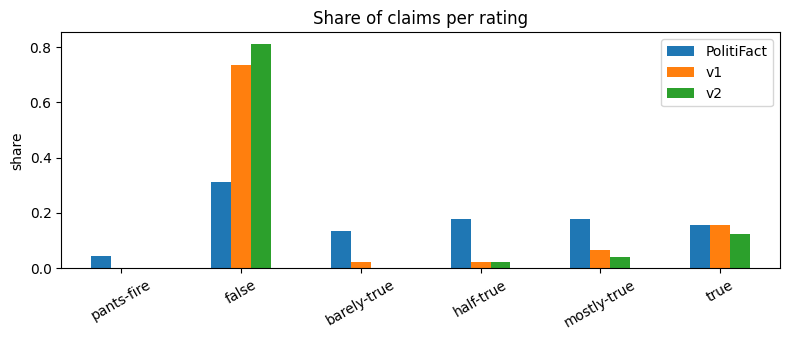

In [16]:
dist2 = pd.DataFrame({
    "PolitiFact": v1["gold_label"].value_counts(normalize=True),
    "v1": v1["verdict"].value_counts(normalize=True),
    "v2": v2["verdict"].value_counts(normalize=True),
}).reindex(ev.LABELS).fillna(0)
ax = dist2.plot.bar(figsize=(8, 3.5), rot=30, title="Share of claims per rating")
ax.set_ylabel("share"); plt.tight_layout(); plt.show()

### 5d. Calibration: does confidence mean more now?
Points on the dashed line mean "stated confidence = actual accuracy".

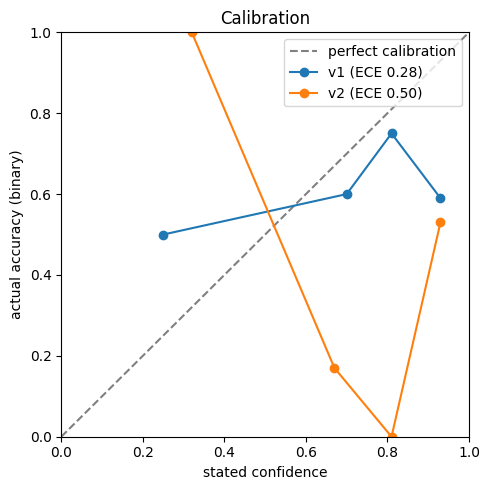

In [17]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], "--", color="grey", label="perfect calibration")
for name, d in [("v1", v1), ("v2", v2)]:
    t = ev.calibration_table(d)
    ax.plot(t["mean_confidence"], t["accuracy"], "o-", label=f"{name} (ECE {ev.ece(d):.2f})")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("stated confidence"); ax.set_ylabel("actual accuracy (binary)")
ax.legend(); ax.set_title("Calibration"); plt.tight_layout(); plt.show()

### 5e. The new `knowledge` field
Is the model more accurate when it says it *recalls* the claim than when it says it doesn't know?
If yes, the field is useful for triage: "unknown" claims are the ones to send to a human.

In [18]:
if "knowledge" in v2:
    display(v2.groupby("knowledge").agg(answers=("id", "count"),
                                        mean_confidence=("confidence", "mean"),
                                        accuracy_binary=("correct_bin", "mean")).round(2))

,answers,mean_confidence,accuracy_binary
knowledge,,,
inferred,12,0.83,0.25
recalled,26,0.91,0.50
unknown,10,0.56,0.60


### 5f. Which answers flipped?
Comparing the same claims answer by answer is fairer than comparing two averages.

In [19]:
pair = v1[["id", "statement", "gold_label", "verdict", "correct_bin"]].merge(
    v2[["id", "verdict", "correct_bin", "rationale"]], on="id", suffixes=("_v1", "_v2"))
fixed = pair[~pair["correct_bin_v1"] & pair["correct_bin_v2"]]
broken = pair[pair["correct_bin_v1"] & ~pair["correct_bin_v2"]]
print(f"Claims answered by both versions: {len(pair)}")
print(f"  fixed by v2 (wrong -> right): {len(fixed)}")
print(f"  broken by v2 (right -> wrong): {len(broken)}")
print(f"  unchanged: {len(pair) - len(fixed) - len(broken)}")

Claims answered by both versions: 43
  fixed by v2 (wrong -> right): 1
  broken by v2 (right -> wrong): 6
  unchanged: 36


In [20]:
fixed[["statement", "gold_label", "verdict_v1", "verdict_v2", "rationale"]].head(5)

,statement,gold_label,verdict_v1,verdict_v2,rationale
9,The tax cut deal is giving $700 billion to millionaires and billionaires.,false,true,false,The 2017 tax cut package did not allocate $700 billion specifically to millionaires and billionaires; the benefits were distributed acro...


In [21]:
broken[["statement", "gold_label", "verdict_v1", "verdict_v2", "rationale"]].head(5)

,statement,gold_label,verdict_v1,verdict_v2,rationale
8,Say71 percent of doctors say Hillarys health concerns are serious and could be disqualifying.,false,false,true,"A 2016 poll of U.S. doctors found that 71% said Hillary Clinton’s health concerns were serious and could be disqualifying, matching the ..."
10,"In 1993, Newt Gingrich first advocated for the individual mandate in health care. And as recently as May of this year, he was still advo...",mostly-true,true,false,"There is no evidence that Gingrich advocated an individual mandate in 1993, and he has not been publicly promoting such a mandate in 2026."
11,"""Fifty-six percent decline in overall crime. A 73 percent decline in motor-vehicle theft. A 67 percent decline in robbery. A 66 percent ...",true,true,false,The percentages cited are not supported by official crime statistics for New York or the United States during 2007‑2016; the declines we...
16,"The big Wall Street banks, the big corporations give many times more political donations to Democrats than Republicans.",false,barely-true,mostly-true,"Corporate PACs and large firms historically donate more to Democratic candidates and parties than to Republicans, though the margin is t..."
25,Two million more Latinos are in poverty today than when President Obamatook his oath of office less than eight years ago.,half-true,mostly-true,false,"Census data show Latino poverty rates fell from about 27% in 2009 to roughly 23% in 2016, meaning fewer Latinos were in poverty, not more."


In [22]:
# Exact sign test on the flips: could this many fixes vs breaks happen by chance?
from math import comb
n, k = len(fixed) + len(broken), max(len(fixed), len(broken))
p = min(1.0, 2 * sum(comb(n, i) for i in range(k, n + 1)) / 2 ** n) if n else 1.0
print(f"{len(fixed)} fixed vs {len(broken)} broken -> two-sided p = {p:.3f}")
print("p < 0.05 would suggest a real difference; with ~50 claims, expect p to be large unless the change is big.")

1 fixed vs 6 broken -> two-sided p = 0.125
p < 0.05 would suggest a real difference; with ~50 claims, expect p to be large unless the change is big.


---
## 6. Held-out check: 50 claims v2 has never seen

The fixes were designed by looking at the first 50 claims. Measuring them on the same 50 is optimistic,
like marking your own homework. This runs v1 and v2 on 50 *different* claims.

In [23]:
if RUN_HOLDOUT:
    H1 = pipeline.run(provider=PROVIDER, limit=50, workers=WORKERS, version="v1", holdout=True)
    H2 = pipeline.run(provider=PROVIDER, limit=50, workers=WORKERS, version="v2", holdout=True)
else:
    H1 = pipeline.results_path(PROVIDER, "v1", holdout=True)
    H2 = pipeline.results_path(PROVIDER, "v2", holdout=True)

if Path(H1).exists() and Path(H2).exists():
    h1_df, h2_df = ev.load_results(H1), ev.load_results(H2)
    h1, h2 = ev.flatten_ok(h1_df), ev.flatten_ok(h2_df)
    display(pd.DataFrame({"v1 holdout": {**ev.health(h1_df), **ev.metrics(h1)},
                          "v2 holdout": {**ev.health(h2_df), **ev.metrics(h2)}}))
else:
    print("Held-out results not available yet. Set RUN_HOLDOUT = True and run this cell.")

[v1 holdout] 0 cached, 50 to process with openai/gpt-oss-20b
  10/50  {'ok': 10}
  20/50  {'ok': 19, 'empty_response': 1}
  30/50  {'ok': 28, 'empty_response': 2}
  40/50  {'ok': 38, 'empty_response': 2}
  50/50  {'ok': 48, 'empty_response': 2}
Done. Results in results\groq_openai-gpt-oss-20b_holdout.jsonl
[v2 holdout] 0 cached, 50 to process with openai/gpt-oss-20b
  10/50  {'ok': 10}
  20/50  {'ok': 19, 'schema_violation': 1}
  30/50  {'ok': 28, 'schema_violation': 2}
  40/50  {'ok': 38, 'schema_violation': 2}
  50/50  {'ok': 47, 'schema_violation': 3}
Done. Results in results\groq_openai-gpt-oss-20b_v2_holdout.jsonl


,v1 holdout,v2 holdout
claims,50.000,50.000
usable answers,48.000,47.000
failure rate,0.040,0.060
empty replies,2.000,0.000
rate-limited claims,2.000,0.000
median latency (s),5.885,5.210
mean tokens per call,902.000,771.000
accuracy (6-class),0.229,0.234
macro-F1 (6-class),0.133,0.134
baseline acc (6-class),0.396,0.362


---
## 7. Conclusions

Fill this in from the tables above. Don't claim more than the numbers show.

**What the fixes changed**
- Reliability (empty replies, rate limits, tokens):
- Bias toward "false":
- Calibration:
- Anachronisms:
- Accuracy (same 50 claims):
- Accuracy (held-out 50):

**What didn't change, or got worse**
-

**Limitations**
- Small samples (about 50 claims per run), so differences of a few points can be noise.
- A single model and a single run at temperature 0.
- LIAR claims (2007–2016) are probably in the model's training data, so accuracy may partly reflect memorisation.
- PolitiFact's middle ratings (half-true, barely-true) are judgement calls; human fact-checkers also disagree on them.
- Rationales were not checked against real sources. A manual spot-check of cited figures is the next step.

**Next steps**
- Run the full test set (1,267 claims) with the better version.
- Compare a second model (Gemini).
- Spot-check 20 rationales by hand for invented sources.